# BPE vs WordPiece on Roman Urdu: Results

Run `python run.py` first. This notebook only loads and shows the files in `results/`.

In [1]:
import pandas as pd
from IPython.display import Image, display
metrics = pd.read_csv('results/metrics.csv')
variants = pd.read_csv('results/variants.csv')
downstream = pd.read_csv('results/downstream.csv')

## 1. Intrinsic metrics
Unknown-token rate (%), fertility (tokens per word), % of words split into 2+ tokens, characters per token.

In [2]:
metrics

,algorithm,vocab_size,unk_rate,fertility,continued_words,chars_per_token
0,BPE,1000,0.0,1.685,43.329,2.347
1,BPE,4000,0.0,1.319,23.593,2.998
2,BPE,8000,0.0,1.201,15.767,3.293
3,BPE,16000,0.0,1.127,10.312,3.508
4,WordPiece,1000,0.0,1.807,47.443,2.189
5,WordPiece,4000,0.0,1.365,25.967,2.898
6,WordPiece,8000,0.0,1.226,17.255,3.226
7,WordPiece,16000,0.0,1.142,11.413,3.464


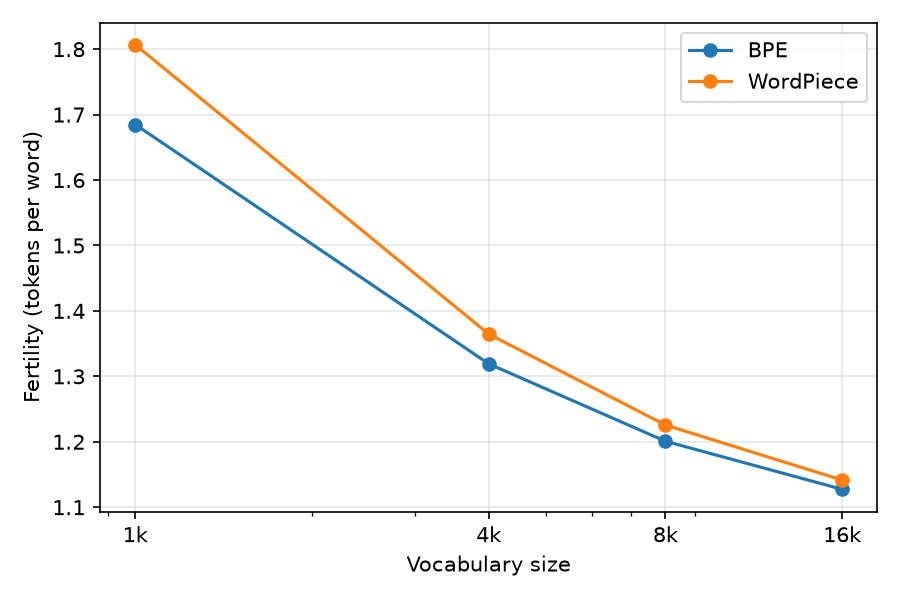

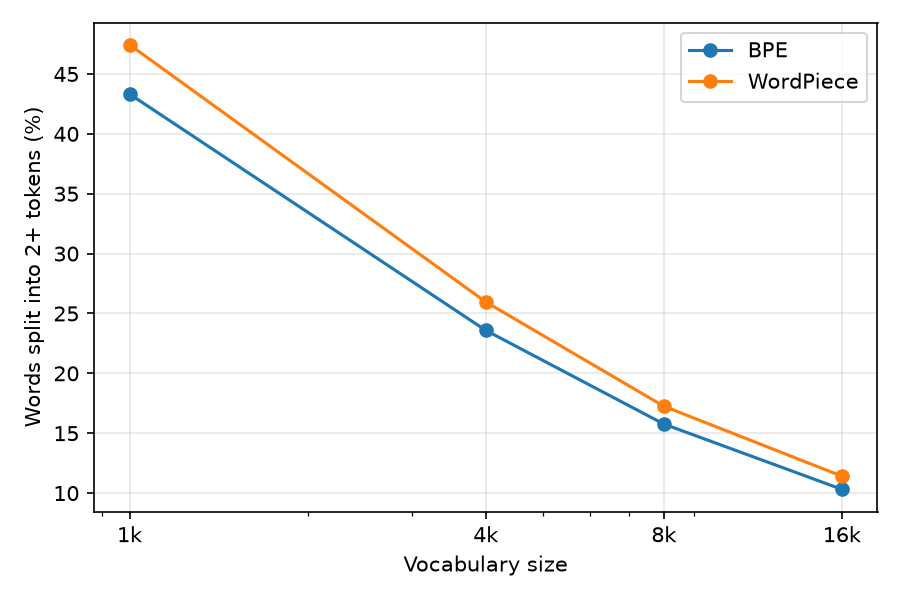

In [3]:
display(Image('results/fertility.png'))
display(Image('results/continued_words.png'))

## 2. Spelling-variant consistency
Mean pairwise Jaccard similarity of the token sets of spelling variants (higher = variants share more pieces).

In [4]:
variants.set_index(['algorithm', 'vocab_size']).T

algorithm     BPE                      WordPiece                     
vocab_size  1000   4000   8000   16000     1000   4000   8000   16000
what        0.167  0.167  0.167  0.167     0.167  0.167  0.167  0.167
no          0.000  0.000  0.000  0.000     0.083  0.000  0.000  0.000
is          0.000  0.000  0.000  0.000     0.000  0.000  0.000  0.000
good        0.167  0.167  0.167  0.000     0.250  0.167  0.167  0.000
good (f)    0.111  0.111  0.111  0.111     0.067  0.111  0.111  0.111
very        0.000  0.000  0.000  0.000     0.056  0.000  0.000  0.000
me          0.000  0.000  0.000  0.000     0.000  0.000  0.000  0.000
why         0.000  0.000  0.000  0.000     0.000  0.000  0.000  0.000
friend      0.167  0.167  0.167  0.167     0.222  0.167  0.167  0.167
fine        0.111  0.000  0.000  0.000     0.167  0.000  0.000  0.000
brother     0.111  0.111  0.000  0.000     0.167  0.111  0.167  0.167
pakistan    0.000  0.000  0.000  0.000     0.056  0.083  0.000  0.000
life        0.000  0.000  0.000  0.000     0.083  0.000  0.000  0.000
happy       0.000  0.000  0.000  0.000     0.222  0.000  0.000  0.000
god         0.167  0.167  0.167  0.167     0.083  0.167  0.167  0.167
thanks      0.550  0.167  0.167  0.167     0.550  0.167  0.167  0.167
mean        0.097  0.066  0.059  0.049     0.136  0.071  0.069  0.059

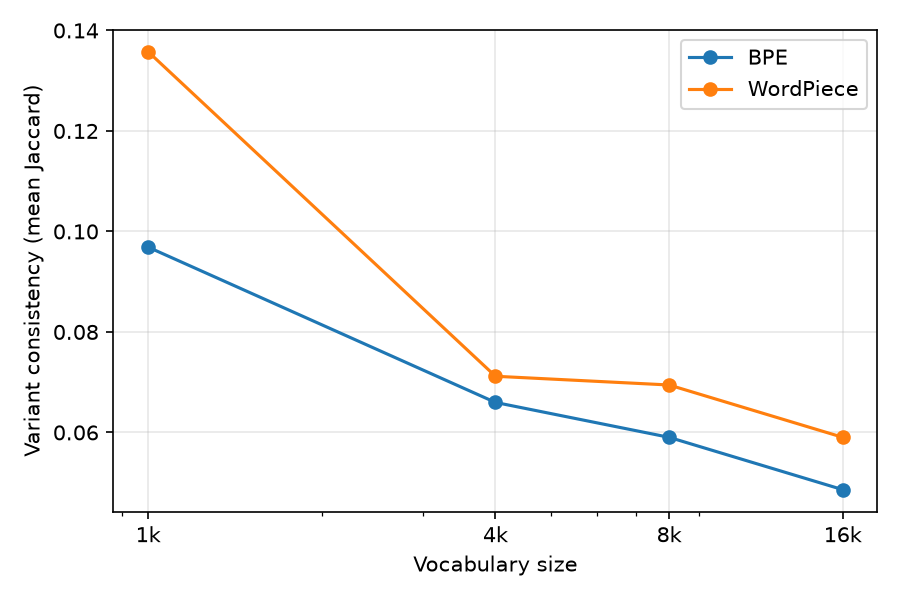

In [5]:
display(Image('results/variants.png'))

## 3. Downstream sentiment classification
TF-IDF + Logistic Regression on each tokenizer's output. Word-level TF-IDF is the baseline.

In [6]:
downstream

,algorithm,vocab_size,accuracy,macro_f1
0,BPE,1000.0,61.01,58.95
1,BPE,4000.0,64.52,63.01
2,BPE,8000.0,64.26,62.59
3,BPE,16000.0,65.01,63.26
4,WordPiece,1000.0,61.06,58.98
5,WordPiece,4000.0,64.91,63.37
6,WordPiece,8000.0,64.78,63.07
7,WordPiece,16000.0,64.39,62.63
8,Word-level,NaN,64.78,63.13


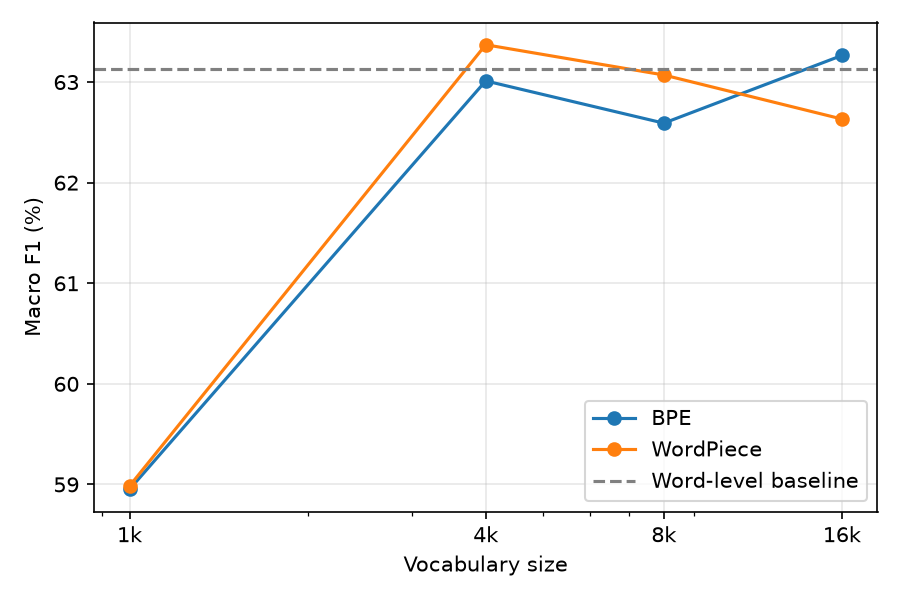

In [7]:
display(Image('results/macro_f1.png'))

## 4. Example tokenizations

In [8]:
from tokenizers import Tokenizer
sentence = 'yaar ye movie bohat achi thi lekin ending nahin samajh ayi'
for name in ['bpe_1000', 'bpe_16000', 'wordpiece_1000', 'wordpiece_16000']:
    tok = Tokenizer.from_file(f'results/tokenizers/{name}.json')
    print(f'{name:16}', tok.encode(sentence).tokens)

bpe_1000         ['yaar', 'ye', 'mo', 'vi', 'e', 'bohat', 'achi', 'thi', 'lekin', 'end', 'ing', 'na', 'hin', 'sa', 'maj', 'h', 'ay', 'i']
bpe_16000        ['yaar', 'ye', 'movie', 'bohat', 'achi', 'thi', 'lekin', 'ending', 'nahin', 'samajh', 'ayi']
wordpiece_1000   ['ya', '##ar', 'ye', 'mo', '##vi', '##e', 'bohat', 'achi', 'thi', 'lekin', 'en', '##di', '##n', '##g', 'nahi', '##n', 'sam', '##a', '##jh', 'ay', '##i']
wordpiece_16000  ['yaar', 'ye', 'movie', 'bohat', 'achi', 'thi', 'lekin', 'ending', 'nahin', 'samajh', 'ayi']
